# Zomato Restaurant Dataset - Exploratory Data Analysis

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
df = pd.read_csv("Zomato-data-.csv")


In [3]:
df.head()

,name,online_order,book_table,rate,votes,approx_cost(for two people),listed_in(type)
0,Jalsa,Yes,Yes,4.1/5,775,800,Buffet
1,Spice Elephant,Yes,No,4.1/5,787,800,Buffet
2,San Churro Cafe,Yes,No,3.8/5,918,800,Buffet
3,Addhuri Udupi Bhojana,No,No,3.7/5,88,300,Buffet
4,Grand Village,No,No,3.8/5,166,600,Buffet


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 148 entries, 0 to 147
Data columns (total 7 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   name                         148 non-null    str  
 1   online_order                 148 non-null    str  
 2   book_table                   148 non-null    str  
 3   rate                         148 non-null    str  
 4   votes                        148 non-null    int64
 5   approx_cost(for two people)  148 non-null    int64
 6   listed_in(type)              148 non-null    str  
dtypes: int64(2), str(5)
memory usage: 8.2 KB


In [5]:
df.tail()

,name,online_order,book_table,rate,votes,approx_cost(for two people),listed_in(type)
143,Melting Melodies,No,No,3.3/5,0,100,Dining
144,New Indraprasta,No,No,3.3/5,0,150,Dining
145,Anna Kuteera,Yes,No,4.0/5,771,450,Dining
146,Darbar,No,No,3.0/5,98,800,Dining
147,Vijayalakshmi,Yes,No,3.9/5,47,200,Dining


## Cleaning
The `rate` column is stored as text like `4.1/5` (with inconsistent spacing). Pull out the numeric rating.

In [6]:
df["rate"] = df["rate"].astype(str).str.replace(" ", "", regex=False)
df["rate"] = df["rate"].str.split("/").str[0]
df["rate"] = pd.to_numeric(df["rate"], errors="coerce")
df = df.dropna(subset=["rate"])
df.head()


,name,online_order,book_table,rate,votes,approx_cost(for two people),listed_in(type)
0,Jalsa,Yes,Yes,4.1,775,800,Buffet
1,Spice Elephant,Yes,No,4.1,787,800,Buffet
2,San Churro Cafe,Yes,No,3.8,918,800,Buffet
3,Addhuri Udupi Bhojana,No,No,3.7,88,300,Buffet
4,Grand Village,No,No,3.8,166,600,Buffet


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 148 entries, 0 to 147
Data columns (total 7 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   name                         148 non-null    str    
 1   online_order                 148 non-null    str    
 2   book_table                   148 non-null    str    
 3   rate                         148 non-null    float64
 4   votes                        148 non-null    int64  
 5   approx_cost(for two people)  148 non-null    int64  
 6   listed_in(type)              148 non-null    str    
dtypes: float64(1), int64(2), str(4)
memory usage: 8.2 KB


In [8]:
df["online_order"].value_counts()

online_order
No     90
Yes    58
Name: count, dtype: int64

In [9]:
df["book_table"].value_counts()

book_table
No     140
Yes      8
Name: count, dtype: int64

In [10]:
df["listed_in(type)"].value_counts()

listed_in(type)
Dining    110
Cafes      23
other       8
Buffet      7
Name: count, dtype: int64

In [11]:
df["name"].value_counts()

name
San Churro Cafe     2
Onesta              2
CAFE NOVA           2
Jalsa               1
Spice Elephant      1
                   ..
Melting Melodies    1
New Indraprasta     1
Anna Kuteera        1
Darbar              1
Vijayalakshmi       1
Name: count, Length: 145, dtype: int64

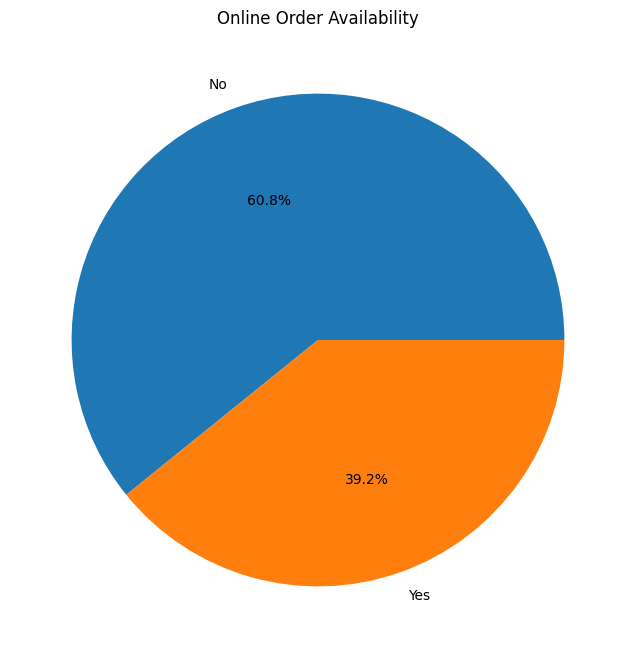

In [12]:
online_order = df['online_order'].value_counts()

plt.figure(figsize=(8, 8))
plt.pie(online_order, labels=online_order.index, autopct='%1.1f%%')
plt.title('Online Order Availability')
plt.show()


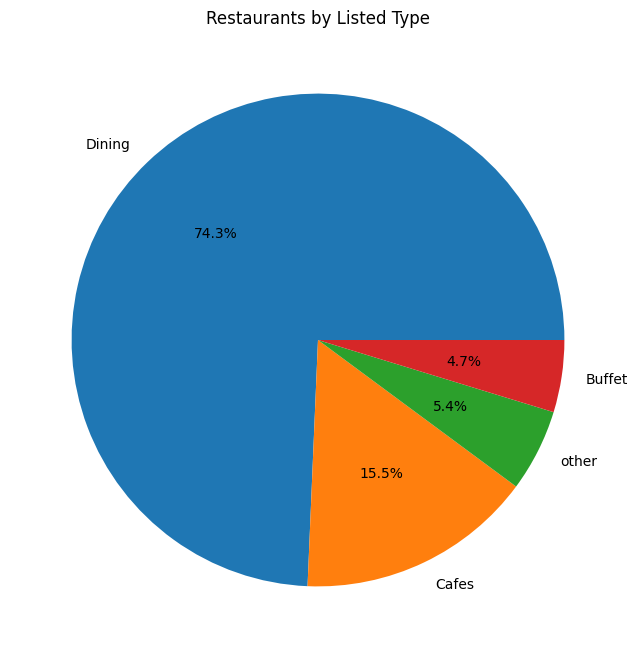

In [13]:
listed_type = df['listed_in(type)'].value_counts()

plt.figure(figsize=(8, 8))
plt.pie(listed_type, labels=listed_type.index, autopct='%1.1f%%')
plt.title('Restaurants by Listed Type')
plt.show()


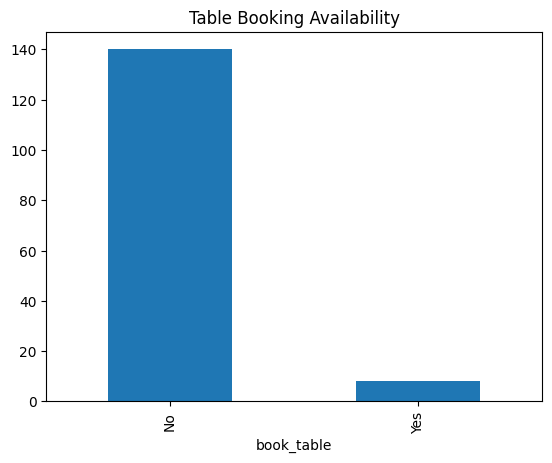

In [14]:
book_table_cnt = df['book_table'].value_counts()
book_table_cnt.plot(kind='bar')
plt.title("Table Booking Availability")
plt.xlabel("book_table")
plt.show()


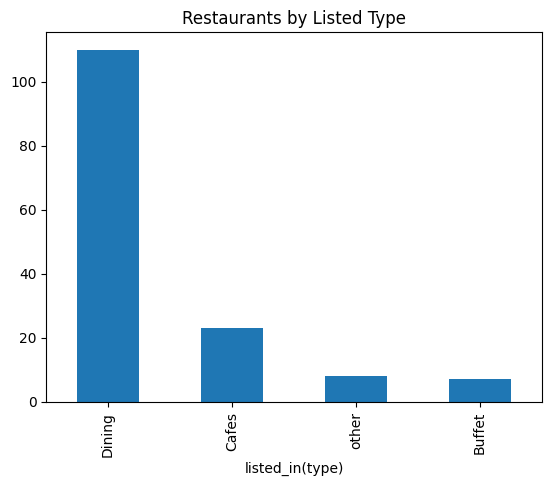

In [15]:
listed_type_cnt = df['listed_in(type)'].value_counts()
listed_type_cnt.plot(kind='bar')
plt.title("Restaurants by Listed Type")
plt.xlabel("listed_in(type)")
plt.show()


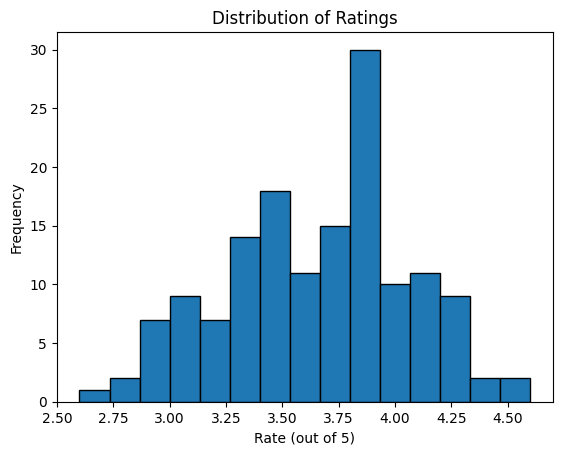

In [16]:
df["rate"].plot(kind="hist", bins=15, edgecolor="black")
plt.title("Distribution of Ratings")
plt.xlabel("Rate (out of 5)")
plt.show()


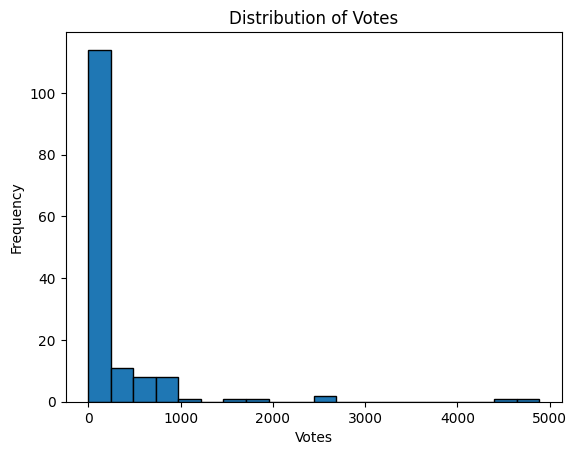

In [17]:
df["votes"].plot(kind="hist", bins=20, edgecolor="black")
plt.title("Distribution of Votes")
plt.xlabel("Votes")
plt.show()


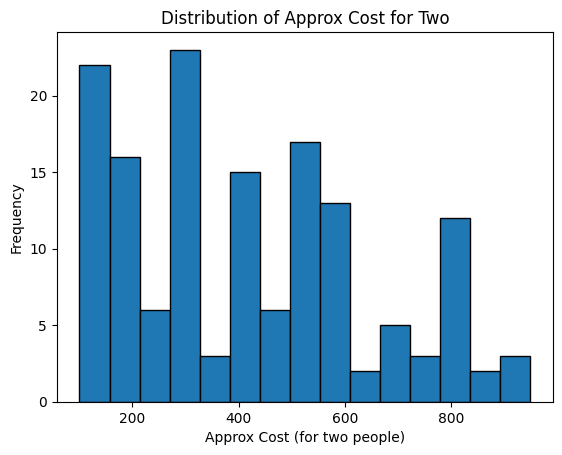

In [18]:
df["approx_cost(for two people)"].plot(kind="hist", bins=15, edgecolor="black")
plt.title("Distribution of Approx Cost for Two")
plt.xlabel("Approx Cost (for two people)")
plt.show()


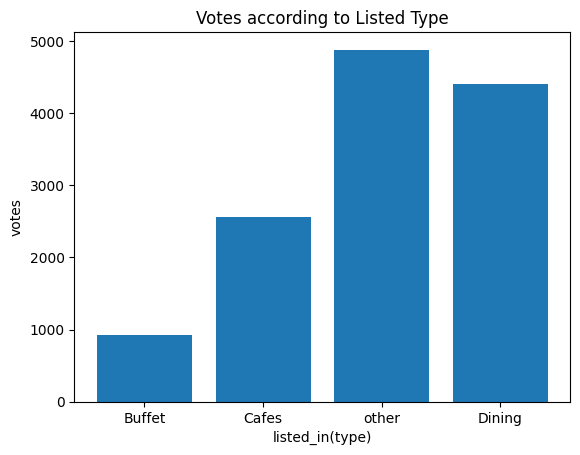

In [19]:
plt.bar(df['listed_in(type)'], df['votes'])
plt.xlabel("listed_in(type)")
plt.ylabel("votes")
plt.title("Votes according to Listed Type")
plt.show()


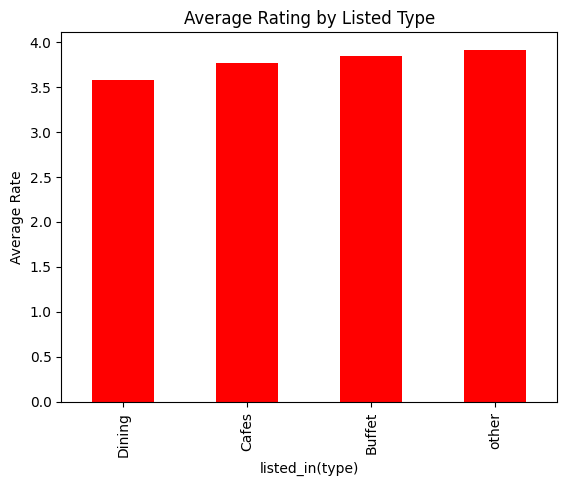

In [20]:
avg_rate_type = df.groupby('listed_in(type)')['rate'].mean().sort_values()
avg_rate_type.plot(kind='bar', color='red')
plt.title("Average Rating by Listed Type")
plt.xlabel("listed_in(type)")
plt.ylabel("Average Rate")
plt.show()


In [21]:
rate_stats = df.groupby("listed_in(type)")["rate"].agg(["max", "min", "mean"])
rate_stats


,max,min,mean
listed_in(type),,,
Buffet,4.1,3.6,3.842857
Cafes,4.6,3.0,3.765217
Dining,4.4,2.6,3.571818
other,4.6,2.8,3.912500


In [22]:
cost_stats = df.groupby("online_order")["approx_cost(for two people)"].agg(["max", "min", "mean"])
cost_stats


,max,min,mean
online_order,,,
No,950,100,358.888889
Yes,850,100,510.344828


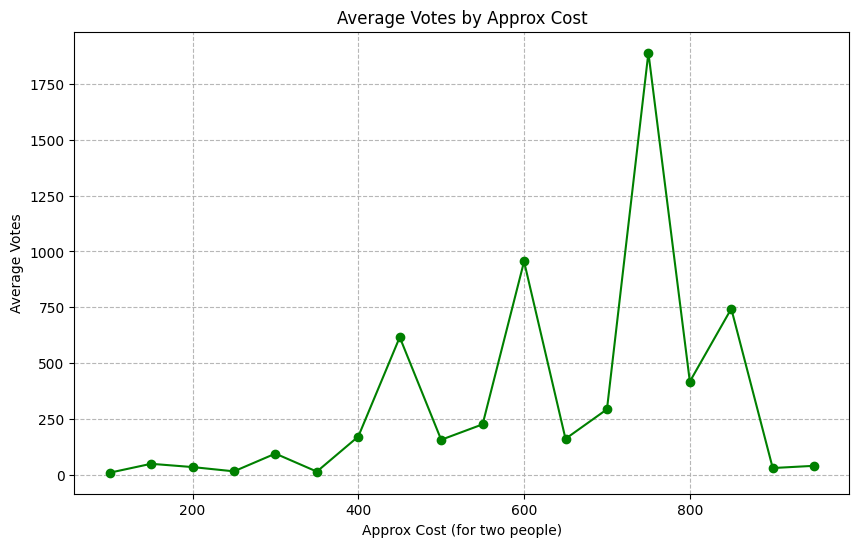

In [23]:
avg_votes_cost = df.groupby('approx_cost(for two people)')['votes'].mean()

plt.figure(figsize=(10, 6))
plt.plot(avg_votes_cost.index, avg_votes_cost.values, marker='o', linestyle='-', color='green')
plt.title('Average Votes by Approx Cost')
plt.xlabel('Approx Cost (for two people)')
plt.ylabel('Average Votes')
plt.grid(True, linestyle='--', alpha=0.9)
plt.show()


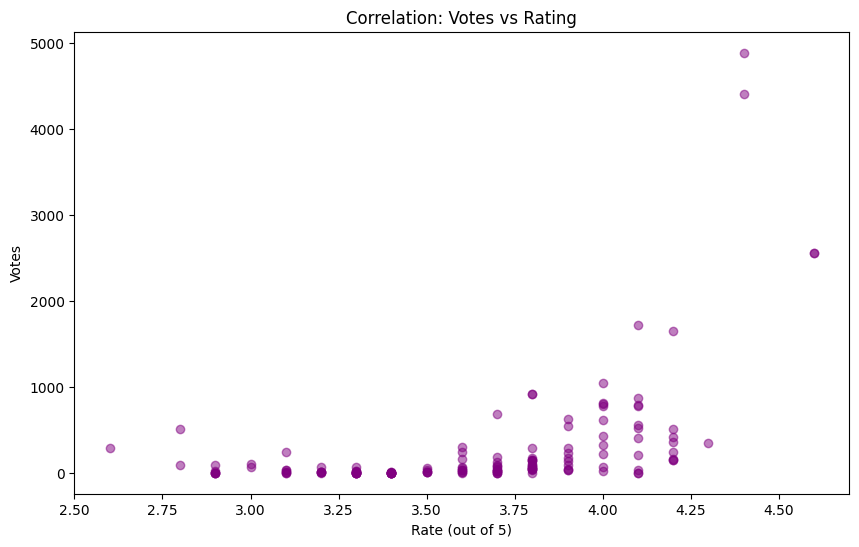

In [24]:
plt.figure(figsize=(10, 6))
plt.scatter(df['rate'], df['votes'], alpha=0.5, color='purple')
plt.title('Correlation: Votes vs Rating')
plt.xlabel('Rate (out of 5)')
plt.ylabel('Votes')
plt.show()


<Figure size 800x600 with 0 Axes>

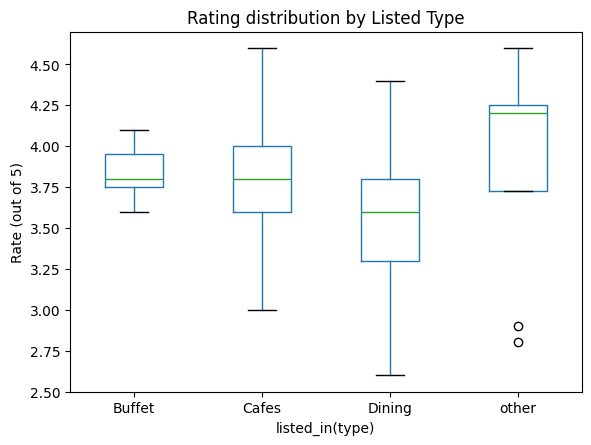

In [25]:
plt.figure(figsize=(8, 6))
df.boxplot(column='rate', by='listed_in(type)', grid=False)
plt.title('Rating distribution by Listed Type')
plt.suptitle('')
plt.ylabel('Rate (out of 5)')
plt.show()


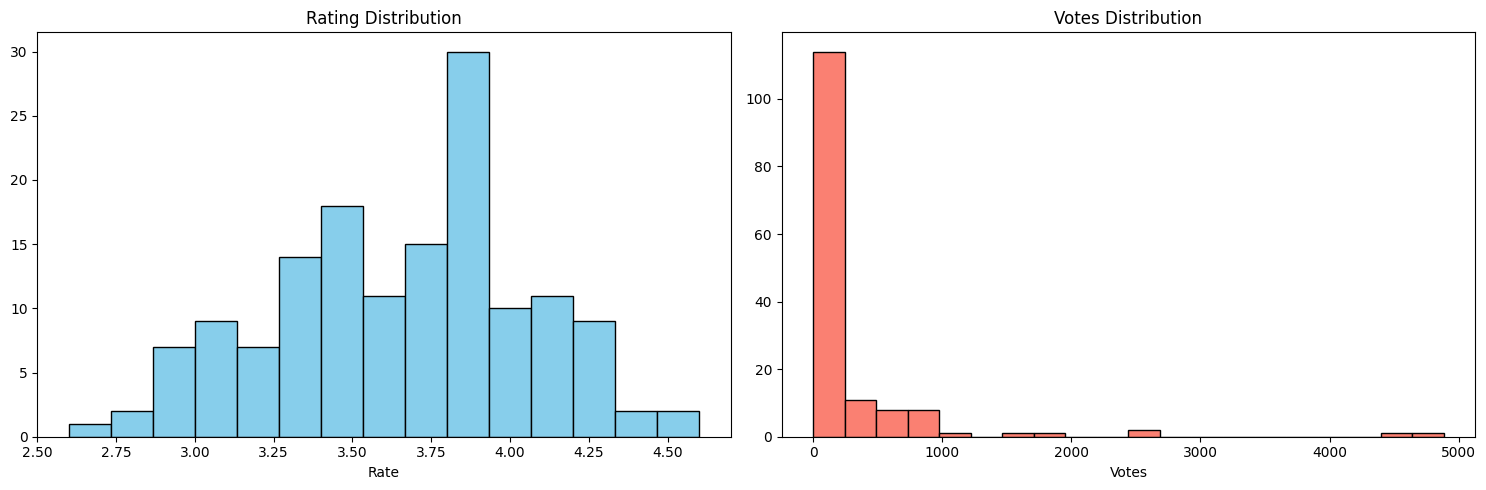

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].hist(df['rate'], bins=15, color='skyblue', edgecolor='black')
axes[0].set_title('Rating Distribution')
axes[0].set_xlabel('Rate')

axes[1].hist(df['votes'], bins=20, color='salmon', edgecolor='black')
axes[1].set_title('Votes Distribution')
axes[1].set_xlabel('Votes')

plt.tight_layout()
plt.show()


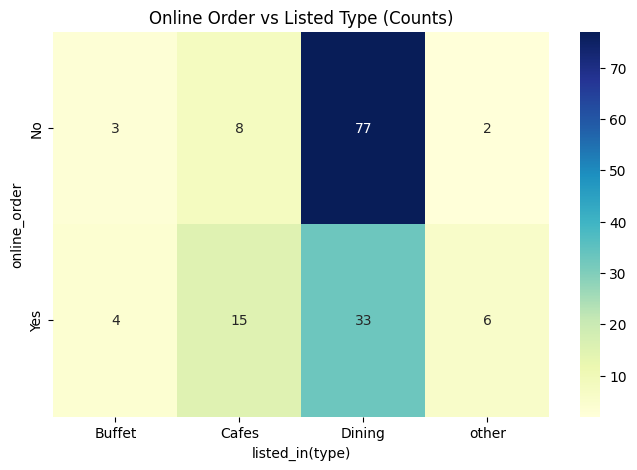

In [27]:
ct_order_type = pd.crosstab(df['online_order'], df['listed_in(type)'])

plt.figure(figsize=(8, 5))
sns.heatmap(ct_order_type, annot=True, fmt="d", cmap="YlGnBu")
plt.title("Online Order vs Listed Type (Counts)")
plt.xlabel("listed_in(type)")
plt.ylabel("online_order")
plt.show()


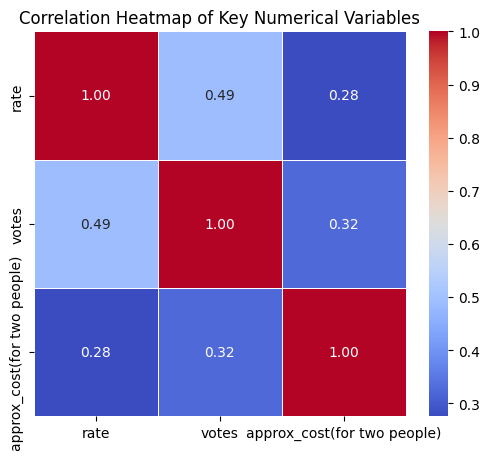

In [28]:
num_cols = ['rate', 'votes', 'approx_cost(for two people)']
corr = df[num_cols].corr()

plt.figure(figsize=(6, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", linewidths=0.5)
plt.title('Correlation Heatmap of Key Numerical Variables')
plt.show()


In [29]:
type_cost_pivot = df.pivot_table(values="approx_cost(for two people)", index="listed_in(type)", aggfunc=["max", "mean", "min"])
type_cost_pivot


,max,mean,min
,approx_cost(for two people),approx_cost(for two people),approx_cost(for two people)
listed_in(type),,,
Buffet,800,671.428571,300
Cafes,900,545.652174,200
Dining,950,357.272727,100
other,800,668.750000,500


In [30]:
total_records = len(df)
avg_rate = df["rate"].mean()
avg_cost = df["approx_cost(for two people)"].sum()
top_type = df["listed_in(type)"].value_counts().idxmax()
best_type_by_rate = df.groupby("listed_in(type)")["rate"].mean().idxmax()
online_order_pct = (len(df[df["online_order"] == "Yes"]) / total_records) * 100

print("Total restaurants analysed:", total_records)
print("Average rating:", round(avg_rate, 2))
print("Total approx cost (sum, for two people):", avg_cost)
print("Most common listed type:", top_type)
print("Best rated listed type on average:", best_type_by_rate)
print("Percentage offering online order:", round(online_order_pct, 2), "%")


Total restaurants analysed: 148
Average rating: 3.63
Total approx cost (sum, for two people): 61900
Most common listed type: Dining
Best rated listed type on average: other
Percentage offering online order: 39.19 %


In [31]:
rate = df['rate'].to_numpy()
votes = df['votes'].to_numpy()
cost = df['approx_cost(for two people)'].to_numpy()

print("Rate:", rate[:5])
print("Votes:", votes[:5])
print("Approx cost:", cost[:5])
print("Rate dtype:", rate.dtype)


Rate: [4.1 4.1 3.8 3.7 3.8]
Votes: [775 787 918  88 166]
Approx cost: [800 800 800 300 600]
Rate dtype: float64


In [32]:
print("Average Rating is:", round(np.mean(rate), 2))
print("Highest Rating found is:", np.max(rate))
print("Lowest Rating found is:", np.min(rate))
print("Highest Votes found is:", np.max(votes))
print("Highest Approx Cost found is:", np.max(cost))


Average Rating is: 3.63
Highest Rating found is: 4.6
Lowest Rating found is: 2.6
Highest Votes found is: 4884
Highest Approx Cost found is: 950


In [33]:
columns = [rate, votes, cost]
column_names = ["Rate", "Votes", "Approx_Cost_For_Two"]

summary_list = []
for data in columns:
    stats = {
        "Mean (Avg)": round(np.mean(data), 2),
        "Std Dev (Spread)": round(np.std(data), 2),
        "Total (Sum)": round(np.sum(data), 2),
        "Highest (Max)": np.max(data),
        "Lowest (Min)": np.min(data),
        "Count": len(data),
    }
    summary_list.append(stats)

summary_table = pd.DataFrame(summary_list, index=column_names)
summary_table


,Mean (Avg),Std Dev (Spread),Total (Sum),Highest (Max),Lowest (Min),Count
Rate,3.63,0.40,537.7,4.6,2.6,148
Votes,264.81,651.46,39192.0,4884.0,0.0,148
Approx_Cost_For_Two,418.24,222.33,61900.0,950.0,100.0,148


In [34]:
summary_table.to_csv("zomato_summary.csv")
print("Saved summary table to zomato_summary.csv")


Saved summary table to zomato_summary.csv
